# 03 · Segments, uplift and business impact

Notebook 02 showed that the men's email is the best on average. Here I answer three more questions:

1. Are there customers who respond better to the women's email, or to neither?
2. Does a model that picks the email for each customer beat "send the men's email to everyone"?
3. How much money is the decision worth?

I only use variables measured before the send. Segmenting by something the email could have changed (for example, having visited the site) would break the randomization.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor

from src.dataset import load, GROUP_ORDER, COLORS, FIGURES, POWERBI
from src.stats_utils import compare_means, compare_proportions, robust_ols, wald_test, holm_adjust, results_table

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = 2024

df = load()
df["recency_tercile"] = pd.qcut(df.recency, 3, labels=["1-3 months", "4-8 months", "9-12 months"]).astype(str)
df["history_tercile"] = pd.qcut(df.history, 3, labels=["1) low", "2) medium", "3) high"]).astype(str)

SEGMENTS = {
    "newbie": "New customer",
    "channel": "Purchase channel",
    "zip_code": "Area",
    "mens": "Bought men's clothing",
    "womens": "Bought women's clothing",
    "recency_tercile": "Months since last purchase",
    "history_tercile": "Spend in the past year",
}

## 1. Exploration and confirmation

With 7 variables and 2 campaigns there are 14 possible interactions. If I test all of them at α = 0.05, it is easy for one to come out "significant" by chance. To avoid that:

1. I split customers at random into two halves (stratified by group).
2. In the exploration half I test the 14 interactions and keep those with p < 0.10.
3. In the confirmation half I test only those, with a Holm adjustment.

Each interaction is tested with a regression `spend ~ T + segment + T × segment` with robust (HC1) errors and a joint Wald test on the interaction terms.

In [2]:
rng = np.random.default_rng(SEED)
df["half"] = ""
for grp, indices in df.groupby("group", observed=True).groups.items():
    idx = np.array(indices)
    rng.shuffle(idx)
    df.loc[idx[: len(idx) // 2], "half"] = "exploration"
    df.loc[idx[len(idx) // 2:], "half"] = "confirmation"

pd.crosstab(df.group, df.half)

half,confirmation,exploration
group,,
Control,10653,10653
Mens,10654,10653
Womens,10694,10693


In [3]:
def p_interaction(data, campaign, variable):
    """Wald test p-value that the effect of `campaign` does not change across levels of `variable`."""
    s = data[data.group.isin([campaign, "Control"])]
    T = (s.group == campaign).astype(float).rename("T")
    D = pd.get_dummies(s[variable].astype(str), prefix=variable, drop_first=True, dtype=float)
    X = pd.concat([pd.Series(1.0, index=s.index, name="const"), T, D, D.mul(T, axis=0).add_prefix("T:")], axis=1)
    table = robust_ols(X, s.spend.to_numpy())
    return wald_test(table, [c for c in X.columns if c.startswith("T:")])


rows = []
for campaign in ["Mens", "Womens"]:
    for variable, name in SEGMENTS.items():
        rows.append({
            "campaign": campaign,
            "segment": name,
            "variable": variable,
            "p_exploration": p_interaction(df[df.half == "exploration"], campaign, variable),
        })
interactions = pd.DataFrame(rows)
interactions["candidate"] = interactions.p_exploration < 0.10
interactions.sort_values("p_exploration").round(4)

,campaign,segment,variable,p_exploration,candidate
7,Womens,New customer,newbie,0.0039,True
8,Womens,Purchase channel,channel,0.0531,True
0,Mens,New customer,newbie,0.2524,False
9,Womens,Area,zip_code,0.2719,False
2,Mens,Area,zip_code,0.3489,False
6,Mens,Spend in the past year,history_tercile,0.4023,False
5,Mens,Months since last purchase,recency_tercile,0.5462,False
13,Womens,Spend in the past year,history_tercile,0.6760,False
4,Mens,Bought women's clothing,womens,0.6989,False
11,Womens,Bought women's clothing,womens,0.7111,False


In [4]:
candidates = interactions[interactions.candidate].copy()
candidates["p_confirmation"] = [
    p_interaction(df[df.half == "confirmation"], r.campaign, r.variable) for r in candidates.itertuples()
]
candidates["p_holm"] = holm_adjust(candidates.p_confirmation)
candidates["confirmed"] = np.where(candidates.p_holm < 0.05, "Yes", "No")
candidates[["campaign", "segment", "p_exploration", "p_confirmation", "p_holm", "confirmed"]].round(4)

,campaign,segment,p_exploration,p_confirmation,p_holm,confirmed
7,Womens,New customer,0.0039,0.7204,1.0000,No
8,Womens,Purchase channel,0.0531,0.9423,1.0000,No


Two interactions looked promising in the exploration half, both for the women's email: by new customer and by purchase channel. Neither repeats in the confirmation half. If I had analyzed all 64,000 customers at once and reported the best interaction, I would have presented a finding that did not hold up on independent data.

## 2. Effect of each campaign by segment

Even though the differences between segments were not confirmed, the table by segment is useful to check whether another campaign would be better for any group. I use all the data and treat it as exploratory.

In [5]:
rows = []
for variable, name in SEGMENTS.items():
    for level, sub in df.groupby(variable):
        for campaign in ["Mens", "Womens"]:
            r = compare_means(sub.loc[sub.group == campaign, "spend"], sub.loc[sub.group == "Control", "spend"],
                              "spend", f"{campaign} vs Control")
            rows.append({
                "segment": name,
                "level": str(level),
                "campaign": campaign,
                "segment_customers": len(sub),
                "control_revenue": r.control,
                "campaign_revenue": r.treatment,
                "effect": r.difference,
                "ci_low": r.ci_low,
                "ci_high": r.ci_high,
            })
by_segment = pd.DataFrame(rows)
by_segment.pivot_table(index=["segment", "level"], columns="campaign", values="effect").round(3)

campaign                                  Mens  Womens
segment                    level                      
Area                       Rural        0.7560  0.5150
                           Surburban    0.8040  0.1770
                           Urban        0.7370  0.6690
Bought men's clothing      0            0.6160  0.6320
                           1            0.8970  0.2560
Bought women's clothing    0            0.6830  0.2780
                           1            0.8410  0.5440
Months since last purchase 1-3 months   1.0480  0.3590
                           4-8 months   0.4620  0.4680
                           9-12 months  0.7930  0.4530
New customer               0            0.5780  0.1140
                           1            0.9600  0.7320
Purchase channel           Multichannel 1.2090  1.1580
                           Phone        0.5640  0.2320
                           Web          0.8500  0.4160
Spend in the past year     1) low       0.5560  0.6480
                           2) medium    0.7110  0.2670
                           3) high      1.0460  0.3560

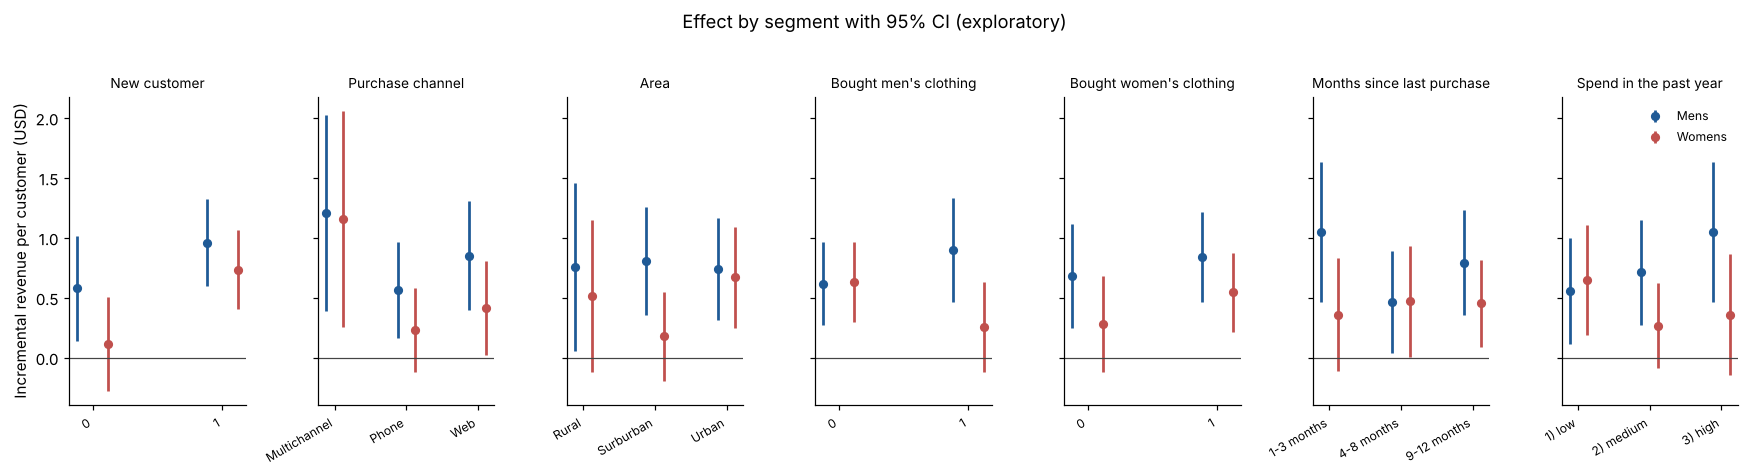

In [6]:
fig, axes = plt.subplots(1, len(SEGMENTS), figsize=(16, 4.2), sharey=True)
for ax, (variable, name) in zip(axes, SEGMENTS.items()):
    sub = by_segment[by_segment.segment == name]
    levels = sub.level.unique()
    x = np.arange(len(levels))
    for offset, campaign in [(-0.12, "Mens"), (0.12, "Womens")]:
        s = sub[sub.campaign == campaign].set_index("level").loc[levels]
        ax.errorbar(x + offset, s.effect, yerr=[s.effect - s.ci_low, s.ci_high - s.effect],
                    fmt="o", color=COLORS[campaign], ms=5, capsize=0, elinewidth=1.8, label=campaign)
    ax.axhline(0, color="#444", lw=0.8)
    ax.set_xticks(x, levels, rotation=30, ha="right", fontsize=8)
    ax.set_title(name, fontsize=9)
axes[0].set_ylabel("Incremental revenue per customer (USD)")
axes[-1].legend(frameon=False, fontsize=8)
fig.suptitle("Effect by segment with 95% CI (exploratory)", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES / "03_effect_by_segment.png", dpi=150, bbox_inches="tight")

In [7]:
best = by_segment.pivot_table(index=["segment", "level"], columns="campaign", values="effect")
print(f"Segments where the women's email has a larger estimated effect than the men's: "
      f"{(best.Womens > best.Mens).sum()} of {len(best)}")
print(best[best.Womens > best.Mens].round(3))

Segments where the women's email has a larger estimated effect than the men's: 3 of 18
campaign                                Mens  Womens
segment                    level                    
Bought men's clothing      0          0.6160  0.6320
Months since last purchase 4-8 months 0.4620  0.4680
Spend in the past year     1) low     0.5560  0.6480


The men's email has a positive estimated effect in every segment. The women's email comes out ahead in only 3 of 18 segments, and by less than 0.10 USD, a tiny difference next to very wide intervals. No segment shows evidence that sending no email would be better.

## 3. Uplift model: pick the email for each customer?

A rule by segment is limited. A model can combine all the variables and pick, for each customer, the email with the highest expected revenue. I use a T-learner: one model per group that predicts the outcome from pre-send variables; for each customer, the predictions of the three models are compared.

Data split (so the evaluation never uses data the model has already seen):

| Set | Use | Share |
|---|---|---|
| Training | Fit the models | 49% |
| Validation | Choose between model variants | 21% |
| Test | Evaluate the final rule once | 30% |

How a rule is evaluated: since assignment was random, the expected revenue of a rule is estimated from the customers whose assigned group matches what the rule would have chosen, weighted by the inverse of the assignment probability (IPW). This compares rules without assuming the model is right.

In [8]:
X = pd.get_dummies(df[["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]], dtype=float)
group = df.group.astype(str)

# Leakage check: the features only describe the customer before the send and each customer belongs to a
# single set, so training, validation and test share no information.
idx_train_full, idx_test = train_test_split(df.index, test_size=0.30, random_state=SEED, stratify=group)
idx_train, idx_valid = train_test_split(idx_train_full, test_size=0.30, random_state=SEED, stratify=group[idx_train_full])
assignment_prob = group.value_counts(normalize=True).to_dict()
print({k: f"{v:.4f}" for k, v in assignment_prob.items()})
print(f"Training: {len(idx_train):,} · Validation: {len(idx_valid):,} · Test: {len(idx_test):,}")

{'Womens': '0.3342', 'Mens': '0.3329', 'Control': '0.3329'}
Training: 31,360 · Validation: 13,440 · Test: 19,200


In [9]:
VARIANTS = {
    "Logistic on conversion": ("classification", lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))),
    "Gradient boosting on conversion": ("classification", lambda: HistGradientBoostingClassifier(
        max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=200, random_state=0)),
    "Ridge on spend": ("regression", lambda: make_pipeline(StandardScaler(), Ridge(alpha=100))),
    "Gradient boosting on spend": ("regression", lambda: HistGradientBoostingRegressor(
        max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=200, random_state=0)),
}


def fit_models(kind, builder, indices):
    target = "conversion" if kind == "classification" else "spend"
    return {g: builder().fit(X.loc[i], df.loc[i, target])
            for g in GROUP_ORDER for i in [indices[group[indices] == g]]}


def predict(models, kind, indices):
    if kind == "classification":
        return pd.DataFrame({g: m.predict_proba(X.loc[indices])[:, 1] for g, m in models.items()}, index=indices)
    return pd.DataFrame({g: m.predict(X.loc[indices]) for g, m in models.items()}, index=indices)


def ipw_contributions(indices, policy):
    """Each customer's contribution to the rule's expected revenue (their mean is the IPW estimator)."""
    g = group[indices].to_numpy()
    weight = np.array([1 / assignment_prob[x] for x in g])
    return df.loc[indices, "spend"].to_numpy() * weight * (g == np.asarray(policy))


def policy_value(indices, policy):
    v = ipw_contributions(indices, policy)
    return v.mean(), v.std(ddof=1) / np.sqrt(len(v))


rows = []
for name, (kind, builder) in VARIANTS.items():
    models = fit_models(kind, builder, idx_train)
    policy = predict(models, kind, idx_valid).idxmax(axis=1).to_numpy()
    value, se = policy_value(idx_valid, policy)
    rows.append({"variant": name, "expected_revenue": value, "std_error": se,
                 "pct_mens": (policy == "Mens").mean(), "pct_womens": (policy == "Womens").mean(),
                 "pct_no_email": (policy == "Control").mean()})
for g in GROUP_ORDER:
    value, se = policy_value(idx_valid, [g] * len(idx_valid))
    rows.append({"variant": f"Simple rule: everyone {g}", "expected_revenue": value, "std_error": se})
validation = pd.DataFrame(rows).set_index("variant")
validation.round(3)

,expected_revenue,std_error,pct_mens,pct_womens,pct_no_email
variant,,,,,
Logistic on conversion,1.6650,0.3030,0.9150,0.0700,0.0150
Gradient boosting on conversion,1.1520,0.2420,0.7970,0.1200,0.0830
Ridge on spend,1.3850,0.2660,0.7710,0.1570,0.0730
Gradient boosting on spend,1.5030,0.2750,0.6750,0.2920,0.0330
Simple rule: everyone Control,0.5780,0.1510,NaN,NaN,NaN
Simple rule: everyone Mens,1.4650,0.2780,NaN,NaN,NaN
Simple rule: everyone Womens,0.8750,0.2000,NaN,NaN,NaN


On validation, logistic regression on conversion gets the highest expected revenue among the models, so it is the variant I take to the test set. This variant ranks the emails by purchase probability, not by expected revenue; that is a reasonable proxy because average order value is similar across the three groups (notebook 02), and the IPW evaluation does use real revenue. Note the standard error: it ranges from 0.24 to 0.30 USD, the same size as the differences between variants. Picking "the best" one here is already close to picking at random, which is why the test evaluation is the one that counts.

### Final evaluation on the test set

I retrain the chosen variant on training + validation and evaluate it once on the test set. The key comparison is against the best simple rule: sending the men's email to everyone. For that difference I use the same customers under both rules (a paired comparison).

In [10]:
kind, builder = VARIANTS["Logistic on conversion"]
final_models = fit_models(kind, builder, idx_train_full)
model_policy = predict(final_models, kind, idx_test).idxmax(axis=1).to_numpy()

rules = {
    "No email": ["Control"] * len(idx_test),
    "Everyone: women's email": ["Womens"] * len(idx_test),
    "Everyone: men's email": ["Mens"] * len(idx_test),
    "Uplift model": model_policy,
}
rows = []
for name, policy in rules.items():
    value, se = policy_value(idx_test, policy)
    rows.append({"rule": name, "revenue_per_customer": value, "ci_low": value - 1.96 * se, "ci_high": value + 1.96 * se})
rule_values = pd.DataFrame(rows).set_index("rule")
print("Model assignment on test:", pd.Series(model_policy).value_counts(normalize=True).round(3).to_dict())
rule_values.round(3)

Model assignment on test: {'Mens': 0.864, 'Womens': 0.133, 'Control': 0.003}


,revenue_per_customer,ci_low,ci_high
rule,,,
No email,0.6220,0.3370,0.9060
Everyone: women's email,1.3020,0.8870,1.7170
Everyone: men's email,1.2910,0.8680,1.7140
Uplift model,1.1380,0.7680,1.5080


In [11]:
diff = ipw_contributions(idx_test, model_policy) - ipw_contributions(idx_test, rules["Everyone: men's email"])
se_diff = diff.std(ddof=1) / np.sqrt(len(diff))
print(f"Uplift model − everyone men's email: {diff.mean():+.3f} USD per customer "
      f"(95% CI: {diff.mean() - 1.96 * se_diff:+.3f} to {diff.mean() + 1.96 * se_diff:+.3f})")

Uplift model − everyone men's email: -0.153 USD per customer (95% CI: -0.406 to +0.100)


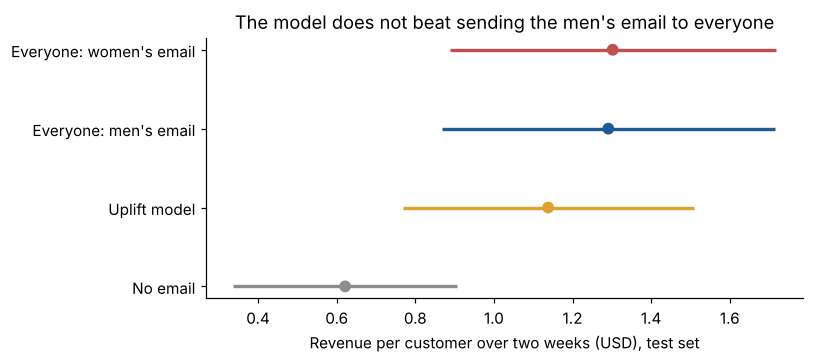

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
order = rule_values.sort_values("revenue_per_customer")
colors = {"No email": COLORS["Control"], "Everyone: women's email": COLORS["Womens"],
          "Everyone: men's email": COLORS["Mens"], "Uplift model": "#E0A030"}
y = np.arange(len(order))
ax.errorbar(order.revenue_per_customer, y, xerr=[order.revenue_per_customer - order.ci_low, order.ci_high - order.revenue_per_customer],
            fmt="none", ecolor=[colors[r] for r in order.index], elinewidth=2.2)
ax.scatter(order.revenue_per_customer, y, color=[colors[r] for r in order.index], zorder=3, s=45)
ax.set_yticks(y, order.index)
ax.set_xlabel("Revenue per customer over two weeks (USD), test set")
ax.set_title("The model does not beat sending the men's email to everyone")
fig.tight_layout()
fig.savefig(FIGURES / "03_policy_value.png", dpi=150, bbox_inches="tight")

The uplift model does not improve on the simple rule: it comes in 0.15 USD per customer lower and the interval for the difference includes zero. With ~580 buyers in the whole experiment, there is not enough signal to personalize.

One detail: on this 30% test set, "everyone gets the women's email" and "everyone gets the men's email" are practically tied, even though with all 64,000 customers the men's email clearly wins (notebook 02). It is the same power problem: the test set has a third of the data and is meant for evaluating the model, not for choosing between campaigns. That decision is made with the full sample.

The recommended rule is the simple one: send the men's email to everyone. It is also easier to run and to explain.

## 4. Business impact

I use the effect estimated with all 64,000 customers (notebook 02), which is more precise than the one from the test set.

In [13]:
effects = []
for campaign in ["Mens", "Womens"]:
    effects.append(compare_means(df.loc[df.group == campaign, "spend"], df.loc[df.group == "Control", "spend"],
                                 "spend", f"{campaign} vs Control"))
effects = results_table(effects)

impact = pd.DataFrame({
    "campaign": ["Mens", "Womens"],
    "incremental_revenue_per_1000_emails": effects.difference.to_numpy() * 1000,
    "ci_low": effects.ci_low.to_numpy() * 1000,
    "ci_high": effects.ci_high.to_numpy() * 1000,
}).set_index("campaign")
impact.round(0)

,incremental_revenue_per_1000_emails,ci_low,ci_high
campaign,,,
Mens,770.0000,485.0000,"1,055.0000"
Womens,424.0000,169.0000,680.0000


Every 1,000 men's emails bring in about 770 USD of additional revenue over two weeks (95% CI: 485 to 1,055).

The dataset has no costs or margins, so what follows are assumptions to show how to make the decision:

- Gross margin: scenarios of 30%, 40% and 50% of revenue.
- Cost per email: bulk email usually costs cents or fractions of a cent; I use 0.01 USD as a reference.

The question is the maximum cost per email at which the campaign still makes a profit, using the lower bound of the interval to stay conservative.

In [14]:
scenarios = []
for margin in [0.30, 0.40, 0.50]:
    for campaign in ["Mens", "Womens"]:
        row = effects[effects.comparison == f"{campaign} vs Control"].iloc[0]
        scenarios.append({
            "margin": f"{margin:.0%}",
            "campaign": campaign,
            "profit_per_email": row.difference * margin,
            "max_cost_per_email": row.ci_low * margin,
            "net_profit_per_1000_at_cost_0.01": (row.difference * margin - 0.01) * 1000,
        })
scenarios = pd.DataFrame(scenarios).set_index(["margin", "campaign"])
scenarios.round(3)

profit_per_email  ...  net_profit_per_1000_at_cost_0.01
margin campaign                    ...                                  
30%    Mens                0.2310  ...                          220.9480
       Womens              0.1270  ...                          117.3240
40%    Mens                0.3080  ...                          297.9310
       Womens              0.1700  ...                          159.7650
50%    Mens                0.3850  ...                          374.9140
       Womens              0.2120  ...                          202.2060

[6 rows x 3 columns]

Even in the most conservative scenario (30% margin and the lower bound of the interval), the men's email makes a profit as long as it costs less than ~0.15 USD per send, far above the typical cost of a bulk email. The decision to send is robust to the assumptions; what really matters is which email is sent.

Scale: on a list like the one in this experiment (64,000 customers), sending the men's email to everyone instead of sending nothing would generate about 49k USD of additional revenue over two weeks, compared with about 27k USD with the women's email.

In [15]:
list_size = len(df)
for campaign in ["Mens", "Womens"]:
    row = effects[effects.comparison == f"{campaign} vs Control"].iloc[0]
    print(f"{campaign}: {row.difference * list_size:,.0f} USD (95% CI: {row.ci_low * list_size:,.0f} to {row.ci_high * list_size:,.0f})")

Mens: 49,269 USD (95% CI: 31,050 to 67,488)
Womens: 27,162 USD (95% CI: 10,814 to 43,511)


## 5. Data for the Power BI report

I export the tables that feed the decision report. Instructions for building it are in [`reports/README.md`](../reports/README.md).

In [16]:
summary = df.groupby("group", observed=True).agg(
    customers=("spend", "size"), visits=("visit", "sum"), buyers=("conversion", "sum"),
    total_revenue=("spend", "sum"), visit_rate=("visit", "mean"), conversion_rate=("conversion", "mean"),
    revenue_per_customer=("spend", "mean"),
).reset_index()
summary.to_csv(POWERBI / "group_summary.csv", index=False)

main = []
for metric, test in [("visit", compare_proportions), ("conversion", compare_proportions), ("spend", compare_means)]:
    for a, b in [("Mens", "Control"), ("Womens", "Control"), ("Mens", "Womens")]:
        main.append(test(df.loc[df.group == a, metric], df.loc[df.group == b, metric], metric, f"{a} vs {b}"))
results_table(main).to_csv(POWERBI / "main_effects.csv", index=False)

by_segment.to_csv(POWERBI / "effects_by_segment.csv", index=False)
rule_values.reset_index().to_csv(POWERBI / "policy_value.csv", index=False)
scenarios.reset_index().to_csv(POWERBI / "impact_scenarios.csv", index=False)

sorted(p.name for p in POWERBI.glob("*.csv"))

['effects_by_segment.csv', 'group_summary.csv', 'impact_scenarios.csv', 'main_effects.csv', 'policy_value.csv']

## Conclusion

| Question | Answer |
|---|---|
| Do some segments respond differently? | Two interactions looked promising, but neither was confirmed in the independent half |
| Is another campaign better for some segment? | No: the men's email has a positive estimated effect in all of them and wins in 15 of 18 segments |
| Does an uplift model improve the decision? | No: on the test set it comes in 0.15 USD per customer below the simple rule (95% CI: −0.41 to +0.10) |
| How much is the decision worth? | ~770 USD per 1,000 emails (95% CI: 485 to 1,055) |

Recommendation: send the men's email to the whole list. As a next experiment, test an improved version of that email against the current one, keeping a no-email control group to keep measuring the incremental effect.